In [1]:
import os

print("Current folder:", os.getcwd())
print("\nFiles in current folder:")
print(os.listdir())

Current folder: C:\Users\ASUS\EV_Charging_Demand_Prediction\notebook

Files in current folder:
['.ipynb_checkpoints', '01_Data_Understanding.ipynb']


In [2]:
import pandas as pd
import numpy as np

df_clean = pd.read_csv(
    "../dataset/ChargingRecords_Feature_Engineered.csv"
)

df_clean["StartDatetime"] = pd.to_datetime(
    df_clean["StartDatetime"]
)

print("Dataset restored successfully!")
print("Shape:", df_clean.shape)

Dataset restored successfully!
Shape: (72826, 19)


In [3]:
feature_columns = [
    "Location",
    "ChargerType",
    "ChargerCompany",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend",
    "TimeOfDay"
]

model_df = df_clean.sort_values("StartDatetime").copy()

X = model_df[feature_columns]
y = model_df["Demand"]

split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (58260, 8)
Testing data: (14566, 8)


In [4]:
import os

checkpoint_path = r"C:\Users\ASUS\EV_Charging_Demand_Prediction\notebook\.ipynb_checkpoints"

for file in os.listdir(checkpoint_path):
    print(file)

01_Data_Understanding-checkpoint.ipynb


# EV Charging Demand Prediction and Usage Pattern Analysis

## Project Objective

To analyze EV charging records, identify usage patterns, predict charging demand, and understand the factors influencing demand.

## Project Workflow

1. Data Understanding
2. Data Cleaning
3. Exploratory Data Analysis
4. Feature Engineering
5. Regression Modeling
6. Classification Modeling
7. Model Explainability
8. Streamlit Dashboard

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("../dataset/ChargingRecords.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (72856, 13)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81


In [3]:
print("Dataset Information")
print("-" * 40)

df.info()

Dataset Information
----------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 72856 entries, 0 to 72855
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72856 non-null  int64  
 1   ChargerID       72856 non-null  int64  
 2   ChargerCompany  72856 non-null  int64  
 3   Location        72856 non-null  str    
 4   ChargerType     72856 non-null  int64  
 5   StartDay        72856 non-null  str    
 6   StartTime       72856 non-null  str    
 7   EndDay          72856 non-null  str    
 8   EndTime         72856 non-null  str    
 9   StartDatetime   72856 non-null  str    
 10  EndDatetime     72856 non-null  str    
 11  Duration        72856 non-null  int64  
 12  Demand          72856 non-null  float64
dtypes: float64(1), int64(5), str(7)
memory usage: 12.5 MB


In [4]:
# Check missing values
print("Missing Values in Each Column")
print("-" * 40)
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check negative duration
print("Negative Duration Records:", (df["Duration"] < 0).sum())

# Check dataset dimensions
print("\nDataset Shape:", df.shape)

Missing Values in Each Column
----------------------------------------
UserID            0
ChargerID         0
ChargerCompany    0
Location          0
ChargerType       0
StartDay          0
StartTime         0
EndDay            0
EndTime           0
StartDatetime     0
EndDatetime       0
Duration          0
Demand            0
dtype: int64

Duplicate Records: 13
Negative Duration Records: 17

Dataset Shape: (72856, 13)


In [5]:
print("Descriptive Statistics")
print("-" * 40)

display(df.describe())

Descriptive Statistics
----------------------------------------


,UserID,ChargerID,ChargerCompany,ChargerType,Duration,Demand
count,72856.000000,72856.000000,72856.000000,72856.00000,72856.000000,72856.000000
mean,338.164667,525.489212,0.627443,0.20524,151.194054,17.444445
std,553.970996,569.544469,0.483489,0.40388,146.430286,13.492728
min,0.000000,1.000000,0.000000,0.00000,-29.000000,0.010000
25%,0.000000,107.000000,0.000000,0.00000,40.000000,7.530000
50%,62.000000,301.000000,1.000000,0.00000,112.000000,14.100000
75%,407.000000,738.000000,1.000000,0.00000,202.000000,23.200000
max,2501.000000,2671.000000,1.000000,1.00000,1573.000000,97.000000


In [6]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Remove records with negative duration
df_clean = df_clean[df_clean["Duration"] >= 0].copy()

print("Data Cleaning Completed!")
print("-" * 40)

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("Remaining Duplicates:", df_clean.duplicated().sum())
print("Remaining Negative Durations:", 
      (df_clean["Duration"] < 0).sum())
print("Missing Values:", df_clean.isnull().sum().sum())

Data Cleaning Completed!
----------------------------------------
Original Dataset Shape: (72856, 13)
Cleaned Dataset Shape: (72826, 13)
Remaining Duplicates: 0
Remaining Negative Durations: 0
Missing Values: 0


In [7]:
df_clean.to_csv(
    "../dataset/ChargingRecords_Cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [8]:
display(df_clean.head())

print("Final Dataset Information:")
df_clean.info()

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81


Final Dataset Information:
<class 'pandas.DataFrame'>
Index: 72826 entries, 0 to 72855
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72826 non-null  int64  
 1   ChargerID       72826 non-null  int64  
 2   ChargerCompany  72826 non-null  int64  
 3   Location        72826 non-null  str    
 4   ChargerType     72826 non-null  int64  
 5   StartDay        72826 non-null  str    
 6   StartTime       72826 non-null  str    
 7   EndDay          72826 non-null  str    
 8   EndTime         72826 non-null  str    
 9   StartDatetime   72826 non-null  str    
 10  EndDatetime     72826 non-null  str    
 11  Duration        72826 non-null  int64  
 12  Demand          72826 non-null  float64
dtypes: float64(1), int64(5), str(7)
memory usage: 13.2 MB


In [9]:
# Convert text columns into datetime format
df_clean["StartDatetime"] = pd.to_datetime(
    df_clean["StartDatetime"]
)

df_clean["EndDatetime"] = pd.to_datetime(
    df_clean["EndDatetime"]
)

print("Datetime conversion completed!")

print("\nStartDatetime datatype:",
      df_clean["StartDatetime"].dtype)

print("EndDatetime datatype:",
      df_clean["EndDatetime"].dtype)

Datetime conversion completed!

StartDatetime datatype: datetime64[us]
EndDatetime datatype: datetime64[us]


In [10]:
print("Dataset Date Range")
print("-" * 40)

print("Earliest Charging Date:",
      df_clean["StartDatetime"].min())

print("Latest Charging Date:",
      df_clean["StartDatetime"].max())

print("Total Unique Locations:",
      df_clean["Location"].nunique())

print("Total Unique Users:",
      df_clean["UserID"].nunique())

print("Total Unique Chargers:",
      df_clean["ChargerID"].nunique())

Dataset Date Range
----------------------------------------
Earliest Charging Date: 2021-09-30 17:14:00
Latest Charging Date: 2022-09-30 23:11:00
Total Unique Locations: 14
Total Unique Users: 2337
Total Unique Chargers: 2118


In [11]:
print("Charging Duration and Demand Analysis")
print("-" * 40)

print("Average Duration:",
      round(df_clean["Duration"].mean(), 2), "minutes")

print("Median Duration:",
      df_clean["Duration"].median(), "minutes")

print("Average Demand:",
      round(df_clean["Demand"].mean(), 2))

print("Median Demand:",
      df_clean["Demand"].median())

print("Maximum Demand:",
      df_clean["Demand"].max())

Charging Duration and Demand Analysis
----------------------------------------
Average Duration: 151.22 minutes
Median Duration: 112.0 minutes
Average Demand: 17.44
Median Demand: 14.1
Maximum Demand: 97.0


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

print("Visualization setup completed!")

Visualization setup completed!


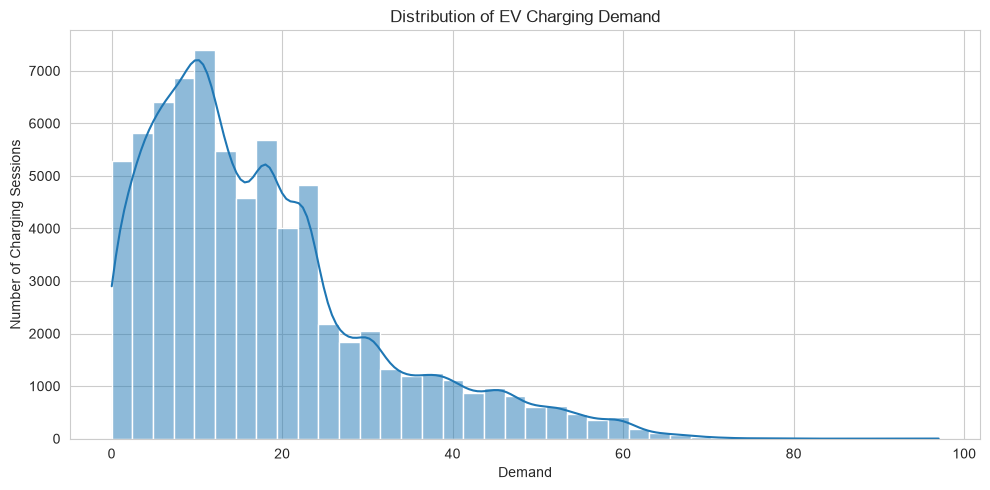

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["Demand"],
    bins=40,
    kde=True
)

plt.title("Distribution of EV Charging Demand")
plt.xlabel("Demand")
plt.ylabel("Number of Charging Sessions")

plt.tight_layout()
plt.show()

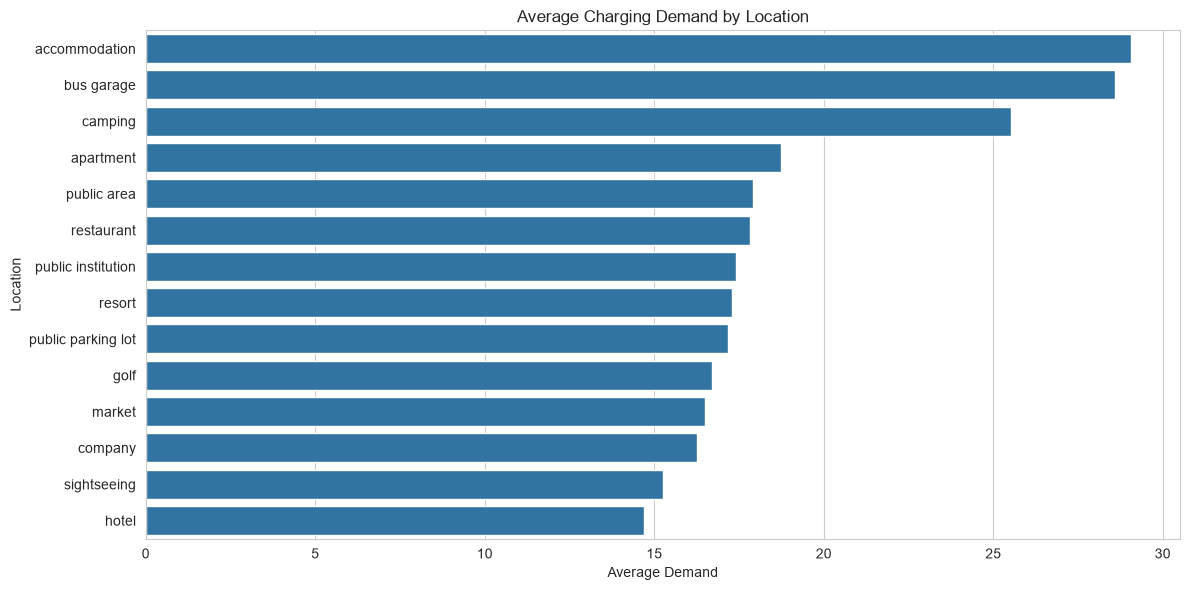

In [14]:
location_demand = (
    df_clean.groupby("Location")["Demand"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=location_demand.values,
    y=location_demand.index
)

plt.title("Average Charging Demand by Location")
plt.xlabel("Average Demand")
plt.ylabel("Location")

plt.tight_layout()
plt.show()

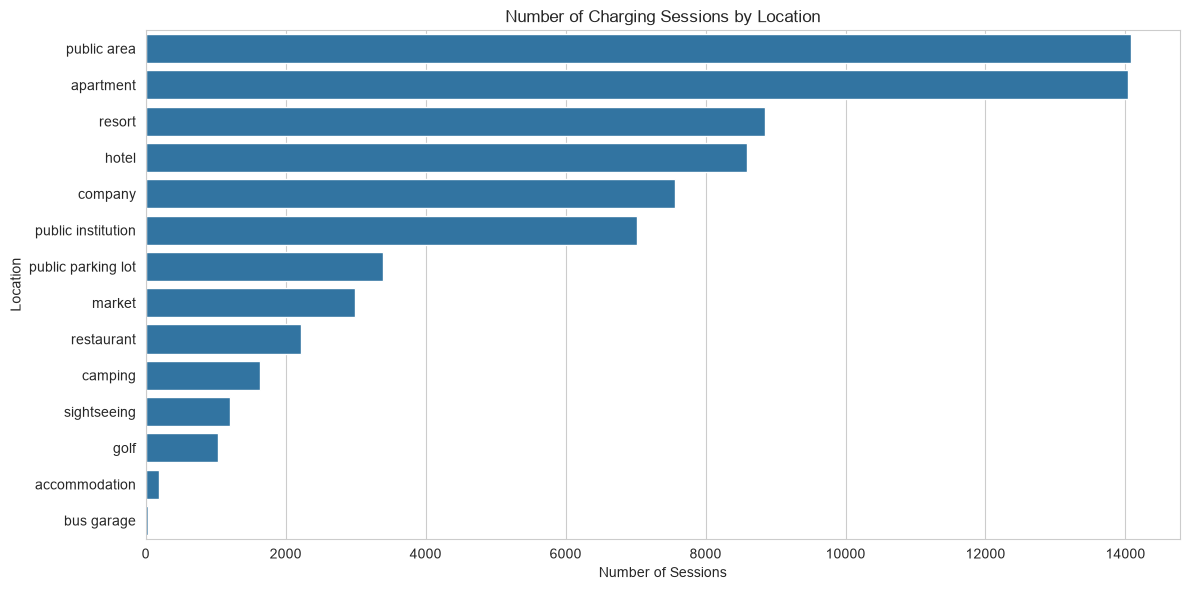

In [15]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_clean,
    y="Location",
    order=df_clean["Location"].value_counts().index
)

plt.title("Number of Charging Sessions by Location")
plt.xlabel("Number of Sessions")
plt.ylabel("Location")

plt.tight_layout()
plt.show()

## Exploratory Data Analysis – Key Findings

1. The dataset contains 72,856 charging records before cleaning.
2. There are 13 duplicate records and 17 records with negative charging duration.
3. After cleaning, 72,826 records remain.
4. No missing values were found.
5. The average charging duration is approximately 151.22 minutes.
6. The average demand is approximately 17.44.
7. The median demand is 14.10.
8. The demand distribution is right-skewed, indicating that most sessions have lower demand.
9. Average demand varies across charging locations.
10. Charging-session volume also varies significantly across locations.

## Conclusion

The dataset is suitable for further analysis and machine learning.
The cleaned dataset will be used for feature engineering,
regression modelling, classification modelling, and demand prediction.

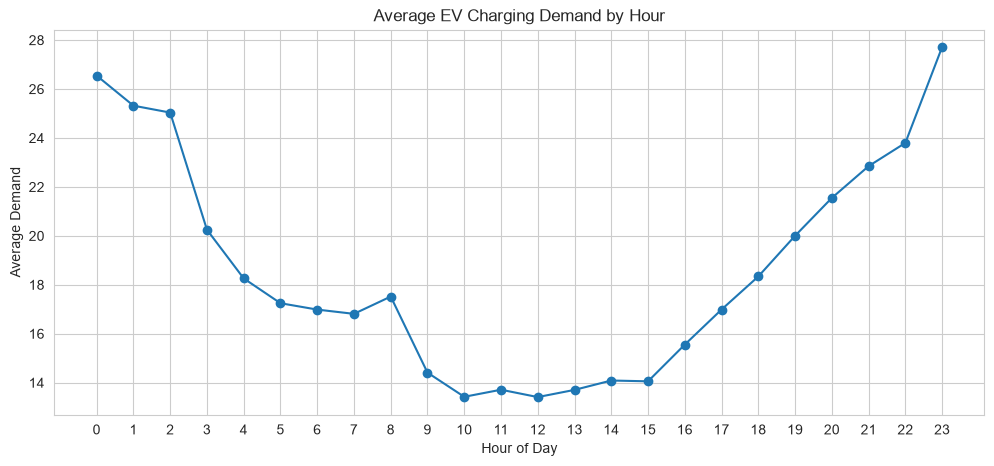

In [16]:
# Convert StartDatetime to datetime format if needed
df_clean["StartDatetime"] = pd.to_datetime(df_clean["StartDatetime"])

# Extract hour from charging start time
df_clean["Hour"] = df_clean["StartDatetime"].dt.hour

# Calculate average demand by hour
hourly_demand = df_clean.groupby("Hour")["Demand"].mean()

# Plot hourly demand
plt.figure(figsize=(12, 5))
hourly_demand.plot(kind="line", marker="o")

plt.title("Average EV Charging Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Demand")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

## Time-Based Charging Demand Analysis

This analysis examines how EV charging demand changes throughout the day.
It helps identify hours with higher and lower charging demand.

In [17]:
# Average demand by day of the week
weekday_demand = df_clean.groupby("DayOfWeek")["Demand"].mean()

# Day names
day_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_demand.index = day_names

# Plot
plt.figure(figsize=(10, 5))
weekday_demand.plot(kind="bar")

plt.title("Average EV Charging Demand by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Demand")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

print("Average Demand by Day:")
display(weekday_demand)

KeyError: 'DayOfWeek'

In [18]:
# Ensure StartDatetime is in datetime format
df_clean["StartDatetime"] = pd.to_datetime(df_clean["StartDatetime"])

# Extract day of the week
df_clean["DayOfWeek"] = df_clean["StartDatetime"].dt.dayofweek

print("DayOfWeek column created successfully!")
print(df_clean[["StartDatetime", "DayOfWeek"]].head())

DayOfWeek column created successfully!
        StartDatetime  DayOfWeek
0 2022-09-15 20:54:00          3
1 2022-09-14 20:01:00          2
2 2022-09-14 18:54:00          2
3 2022-09-29 18:32:00          3
4 2022-09-25 19:30:00          6


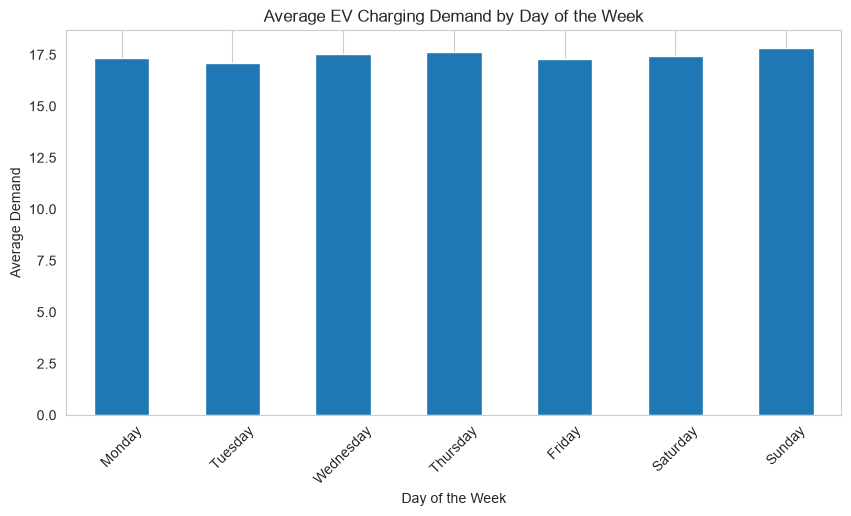

Average Demand by Day:


Monday       17.352914
Tuesday      17.101514
Wednesday    17.527834
Thursday     17.622935
Friday       17.305333
Saturday     17.414715
Sunday       17.805584
Name: Demand, dtype: float64

In [19]:
weekday_demand = df_clean.groupby("DayOfWeek")["Demand"].mean()

day_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_demand.index = day_names

plt.figure(figsize=(10, 5))
weekday_demand.plot(kind="bar")

plt.title("Average EV Charging Demand by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Demand")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

print("Average Demand by Day:")
display(weekday_demand)

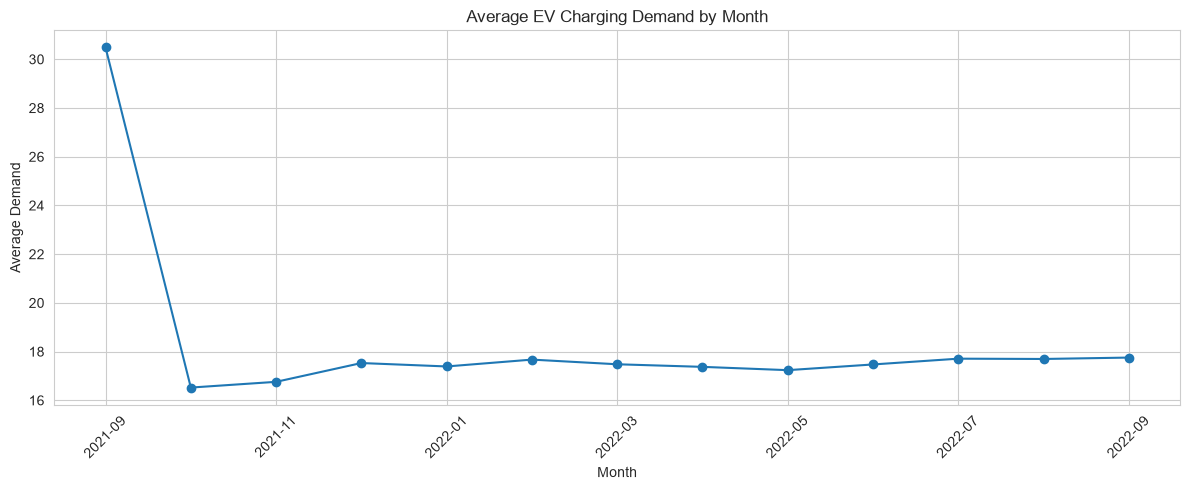

Average Demand by Month:


YearMonth
2021-09    30.483684
2021-10    16.522514
2021-11    16.758129
2021-12    17.529455
2022-01    17.389267
2022-02    17.670372
2022-03    17.479147
2022-04    17.372716
2022-05    17.237415
2022-06    17.471306
2022-07    17.708754
2022-08    17.696557
2022-09    17.753890
Name: Demand, dtype: float64

In [20]:
# Extract month and year
df_clean["YearMonth"] = (
    df_clean["StartDatetime"].dt.to_period("M").astype(str)
)

# Calculate average demand by month
monthly_demand = df_clean.groupby("YearMonth")["Demand"].mean()

# Plot monthly demand
plt.figure(figsize=(12, 5))
monthly_demand.plot(kind="line", marker="o")

plt.title("Average EV Charging Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Demand")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

print("Average Demand by Month:")
display(monthly_demand)

In [21]:
required_variables = [
    "linear_model",
    "decision_tree_model",
    "random_forest_model",
    "gradient_model",
    "xgb_model",
    "lightgbm_model"
]

for name in required_variables:
    print(name, ":", name in globals())

linear_model : False
decision_tree_model : False
random_forest_model : False
gradient_model : False
xgb_model : False
lightgbm_model : False


In [22]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

print("All libraries imported successfully!")

All libraries imported successfully!


In [23]:
df = pd.read_csv("../dataset/ChargingRecords_Feature_Engineered.csv")

df["StartDatetime"] = pd.to_datetime(df["StartDatetime"])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (72826, 19)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand,Hour,DayOfWeek,Month,YearMonth,IsWeekend,TimeOfDay
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,20,3,9,2022-09,0,Evening
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,20,2,9,2022-09,0,Evening
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,18,2,9,2022-09,0,Evening
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,18,3,9,2022-09,0,Evening
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,19,6,9,2022-09,1,Evening


In [24]:
feature_columns = [
    "Location",
    "ChargerType",
    "ChargerCompany",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend",
    "TimeOfDay"
]

X = df[feature_columns]
y = df["Demand"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Input features shape: (72826, 8)
Target shape: (72826,)


,Location,ChargerType,ChargerCompany,Hour,DayOfWeek,Month,IsWeekend,TimeOfDay
0,hotel,0,1,20,3,9,0,Evening
1,hotel,0,1,20,2,9,0,Evening
2,hotel,0,1,18,2,9,0,Evening
3,hotel,0,1,18,3,9,0,Evening
4,hotel,0,1,19,6,9,1,Evening


In [25]:
model_df = df.sort_values("StartDatetime").copy()

X = model_df[feature_columns]
y = model_df["Demand"]

split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (58260, 8)
Testing data: (14566, 8)


In [26]:
categorical_features = ["Location", "TimeOfDay"]

numerical_features = [
    "ChargerType",
    "ChargerCompany",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [27]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [28]:
linear_pred = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, linear_pred)
mse = mean_squared_error(y_test, linear_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, linear_pred)

print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

LINEAR REGRESSION RESULTS
-------------------------
MAE: 10.1936
MSE: 177.0961
RMSE: 13.3077
R2 Score: 0.0854


In [29]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(
            max_depth=10,
            random_state=42
        ))
    ]
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [30]:
dt_pred = decision_tree_model.predict(X_test)

dt_mae = mean_absolute_error(y_test, dt_pred)
dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_pred)

print("DECISION TREE RESULTS")
print("---------------------")
print("MAE:", round(dt_mae, 4))
print("MSE:", round(dt_mse, 4))
print("RMSE:", round(dt_rmse, 4))
print("R2 Score:", round(dt_r2, 4))

DECISION TREE RESULTS
---------------------
MAE: 10.2252
MSE: 179.8568
RMSE: 13.4111
R2 Score: 0.0712


In [31]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [32]:
rf_pred = random_forest_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("RANDOM FOREST RESULTS")
print("---------------------")
print("MAE:", round(rf_mae, 4))
print("MSE:", round(rf_mse, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2 Score:", round(rf_r2, 4))

RANDOM FOREST RESULTS
---------------------
MAE: 10.2461
MSE: 182.5663
RMSE: 13.5117
R2 Score: 0.0572


In [33]:
gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ]
)

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [34]:
gb_pred = gradient_boosting_model.predict(X_test)

gb_mae = mean_absolute_error(y_test, gb_pred)
gb_mse = mean_squared_error(y_test, gb_pred)
gb_rmse = np.sqrt(gb_mse)
gb_r2 = r2_score(y_test, gb_pred)

print("GRADIENT BOOSTING RESULTS")
print("-------------------------")
print("MAE:", round(gb_mae, 4))
print("MSE:", round(gb_mse, 4))
print("RMSE:", round(gb_rmse, 4))
print("R2 Score:", round(gb_r2, 4))

GRADIENT BOOSTING RESULTS
-------------------------
MAE: 10.0916
MSE: 173.6174
RMSE: 13.1764
R2 Score: 0.1034


In [35]:
xgboost_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", XGBRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=5,
            random_state=42,
            objective="reg:squarederror",
            n_jobs=-1
        ))
    ]
)

xgboost_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [36]:
xgb_pred = xgboost_model.predict(X_test)

xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_mse = mean_squared_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(xgb_mse)
xgb_r2 = r2_score(y_test, xgb_pred)

print("XGBOOST RESULTS")
print("----------------")
print("MAE:", round(xgb_mae, 4))
print("MSE:", round(xgb_mse, 4))
print("RMSE:", round(xgb_rmse, 4))
print("R2 Score:", round(xgb_r2, 4))

XGBOOST RESULTS
----------------
MAE: 10.005
MSE: 172.3878
RMSE: 13.1297
R2 Score: 0.1097


In [37]:
lightgbm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LGBMRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=5,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        ))
    ]
)

lightgbm_model.fit(X_train, y_train)

print("LightGBM model trained successfully!")

LightGBM model trained successfully!


In [38]:
lgbm_pred = lightgbm_model.predict(X_test)

lgbm_mae = mean_absolute_error(y_test, lgbm_pred)
lgbm_mse = mean_squared_error(y_test, lgbm_pred)
lgbm_rmse = np.sqrt(lgbm_mse)
lgbm_r2 = r2_score(y_test, lgbm_pred)

print("LIGHTGBM RESULTS")
print("-----------------")
print("MAE:", round(lgbm_mae, 4))
print("MSE:", round(lgbm_mse, 4))
print("RMSE:", round(lgbm_rmse, 4))
print("R2 Score:", round(lgbm_r2, 4))

LIGHTGBM RESULTS
-----------------
MAE: 10.003
MSE: 171.4324
RMSE: 13.0932
R2 Score: 0.1147


In [39]:
regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost",
        "LightGBM"
    ],
    "MAE": [
        10.1936, 10.2252, 10.2461,
        10.0916, 10.0050, 10.0030
    ],
    "MSE": [
        177.0961, 179.8568, 182.5663,
        173.6174, 172.3878, 171.4324
    ],
    "RMSE": [
        13.3077, 13.4111, 13.5117,
        13.1764, 13.1297, 13.0932
    ],
    "R2 Score": [
        0.0854, 0.0712, 0.0572,
        0.1034, 0.1097, 0.1147
    ]
})

regression_results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,10.1936,177.0961,13.3077,0.0854
1,Decision Tree,10.2252,179.8568,13.4111,0.0712
2,Random Forest,10.2461,182.5663,13.5117,0.0572
3,Gradient Boosting,10.0916,173.6174,13.1764,0.1034
4,XGBoost,10.0050,172.3878,13.1297,0.1097
5,LightGBM,10.0030,171.4324,13.0932,0.1147


In [40]:
regression_results.to_csv(
    "../dataset/regression_model_results.csv",
    index=False
)

print("Regression results saved successfully!")

Regression results saved successfully!


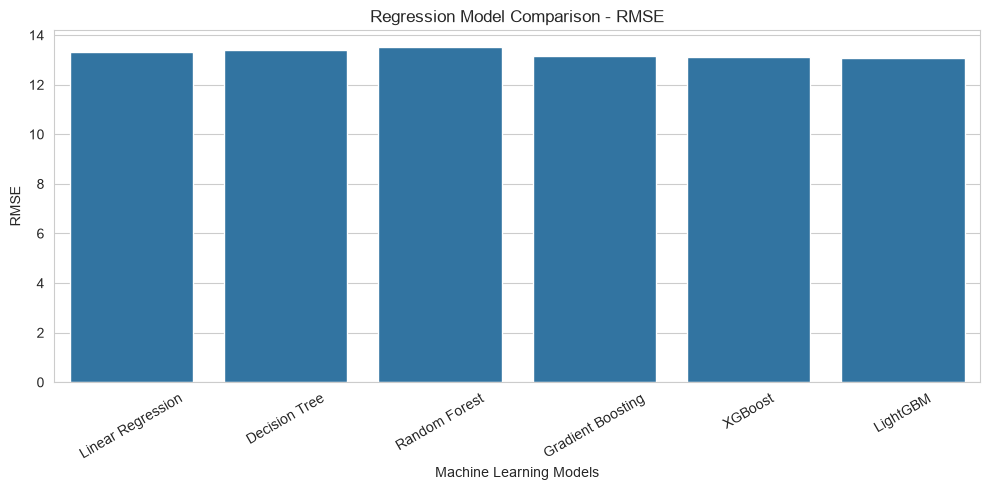

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=regression_results,
    x="Model",
    y="RMSE"
)

plt.title("Regression Model Comparison - RMSE")
plt.xlabel("Machine Learning Models")
plt.ylabel("RMSE")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [42]:
# Create demand categories using the median
demand_threshold = df["Demand"].median()

df["Demand_Category"] = np.where(
    df["Demand"] >= demand_threshold,
    "High",
    "Normal"
)

print("Demand Threshold:", demand_threshold)
print("\nDemand Category Distribution:")
print(df["Demand_Category"].value_counts())

Demand Threshold: 14.1

Demand Category Distribution:
Demand_Category
High      36439
Normal    36387
Name: count, dtype: int64


In [43]:
# Sort data chronologically
model_df = df.sort_values("StartDatetime").copy()

# Select input features
X_class = model_df[feature_columns]

# Select classification target
y_class = model_df["Demand_Category"]

# Split data: 80% training and 20% testing
split_index = int(len(model_df) * 0.80)

X_train_class = X_class.iloc[:split_index]
X_test_class = X_class.iloc[split_index:]

y_train_class = y_class.iloc[:split_index]
y_test_class = y_class.iloc[split_index:]

print("Classification data prepared successfully!")
print("Training features:", X_train_class.shape)
print("Testing features:", X_test_class.shape)

print("\nTraining target distribution:")
print(y_train_class.value_counts())

print("\nTesting target distribution:")
print(y_test_class.value_counts())


Classification data prepared successfully!
Training features: (58260, 8)
Testing features: (14566, 8)

Training target distribution:
Demand_Category
High      29301
Normal    28959
Name: count, dtype: int64

Testing target distribution:
Demand_Category
Normal    7428
High      7138
Name: count, dtype: int64


In [44]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

logistic_model.fit(X_train_class, y_train_class)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predict demand categories
logistic_pred = logistic_model.predict(X_test_class)

# Predict probabilities for ROC-AUC
logistic_prob = logistic_model.predict_proba(X_test_class)[:, 1]

# Calculate evaluation metrics
logistic_accuracy = accuracy_score(y_test_class, logistic_pred)
logistic_precision = precision_score(
    y_test_class, logistic_pred, pos_label="High"
)
logistic_recall = recall_score(
    y_test_class, logistic_pred, pos_label="High"
)
logistic_f1 = f1_score(
    y_test_class, logistic_pred, pos_label="High"
)
logistic_roc_auc = roc_auc_score(
    (y_test_class == "High").astype(int),
    logistic_prob
)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print("Accuracy:", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall:", round(logistic_recall, 4))
print("F1 Score:", round(logistic_f1, 4))
print("ROC-AUC:", round(logistic_roc_auc, 4))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.6326
Precision: 0.6214
Recall: 0.6405
F1 Score: 0.6308
ROC-AUC: 0.3255


In [46]:
print(logistic_model.named_steps["model"].classes_)

['High' 'Normal']


In [47]:
# Find the probability column corresponding to High demand
high_index = list(
    logistic_model.named_steps["model"].classes_
).index("High")

logistic_prob = logistic_model.predict_proba(X_test_class)[:, high_index]

logistic_roc_auc = roc_auc_score(
    (y_test_class == "High").astype(int),
    logistic_prob
)

print("Corrected ROC-AUC:", round(logistic_roc_auc, 4))

Corrected ROC-AUC: 0.6745


In [48]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_classifier = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            max_depth=10,
            random_state=42
        ))
    ]
)

decision_tree_classifier.fit(
    X_train_class,
    y_train_class
)

print("Decision Tree Classifier trained successfully!")

Decision Tree Classifier trained successfully!


In [49]:
# Predict demand categories
dt_pred = decision_tree_classifier.predict(X_test_class)

# Find probability column for High demand
dt_high_index = list(
    decision_tree_classifier.named_steps["model"].classes_
).index("High")

dt_prob = decision_tree_classifier.predict_proba(
    X_test_class
)[:, dt_high_index]

# Calculate evaluation metrics
dt_accuracy = accuracy_score(y_test_class, dt_pred)

dt_precision = precision_score(
    y_test_class, dt_pred, pos_label="High"
)

dt_recall = recall_score(
    y_test_class, dt_pred, pos_label="High"
)

dt_f1 = f1_score(
    y_test_class, dt_pred, pos_label="High"
)

dt_roc_auc = roc_auc_score(
    (y_test_class == "High").astype(int),
    dt_prob
)

print("DECISION TREE CLASSIFICATION RESULTS")
print("------------------------------------")
print("Accuracy:", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall:", round(dt_recall, 4))
print("F1 Score:", round(dt_f1, 4))
print("ROC-AUC:", round(dt_roc_auc, 4))

DECISION TREE CLASSIFICATION RESULTS
------------------------------------
Accuracy: 0.6189
Precision: 0.5971
Recall: 0.6835
F1 Score: 0.6374
ROC-AUC: 0.6613


In [50]:
from sklearn.ensemble import RandomForestClassifier

random_forest_classifier = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=15,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_classifier.fit(
    X_train_class,
    y_train_class
)

print("Random Forest Classifier trained successfully!")

Random Forest Classifier trained successfully!


In [51]:
# Predict demand categories
rf_class_pred = random_forest_classifier.predict(X_test_class)

# Find probability column for High demand
rf_high_index = list(
    random_forest_classifier.named_steps["model"].classes_
).index("High")

rf_class_prob = random_forest_classifier.predict_proba(
    X_test_class
)[:, rf_high_index]

# Calculate evaluation metrics
rf_class_accuracy = accuracy_score(y_test_class, rf_class_pred)

rf_class_precision = precision_score(
    y_test_class, rf_class_pred, pos_label="High"
)

rf_class_recall = recall_score(
    y_test_class, rf_class_pred, pos_label="High"
)

rf_class_f1 = f1_score(
    y_test_class, rf_class_pred, pos_label="High"
)

rf_class_roc_auc = roc_auc_score(
    (y_test_class == "High").astype(int),
    rf_class_prob
)

print("RANDOM FOREST CLASSIFICATION RESULTS")
print("------------------------------------")
print("Accuracy:", round(rf_class_accuracy, 4))
print("Precision:", round(rf_class_precision, 4))
print("Recall:", round(rf_class_recall, 4))
print("F1 Score:", round(rf_class_f1, 4))
print("ROC-AUC:", round(rf_class_roc_auc, 4))

RANDOM FOREST CLASSIFICATION RESULTS
------------------------------------
Accuracy: 0.627
Precision: 0.6127
Recall: 0.6492
F1 Score: 0.6304
ROC-AUC: 0.6748


In [52]:
from sklearn.neighbors import KNeighborsClassifier

knn_classifier = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier(
            n_neighbors=5,
            n_jobs=-1
        ))
    ]
)

knn_classifier.fit(
    X_train_class,
    y_train_class
)

print("KNN Classifier trained successfully!")

KNN Classifier trained successfully!


In [53]:
# Predict demand categories
knn_pred = knn_classifier.predict(X_test_class)

# Find probability column for High demand
knn_high_index = list(
    knn_classifier.named_steps["model"].classes_
).index("High")

knn_prob = knn_classifier.predict_proba(
    X_test_class
)[:, knn_high_index]

# Calculate evaluation metrics
knn_accuracy = accuracy_score(y_test_class, knn_pred)

knn_precision = precision_score(
    y_test_class, knn_pred, pos_label="High"
)

knn_recall = recall_score(
    y_test_class, knn_pred, pos_label="High"
)

knn_f1 = f1_score(
    y_test_class, knn_pred, pos_label="High"
)

knn_roc_auc = roc_auc_score(
    (y_test_class == "High").astype(int),
    knn_prob
)

print("KNN CLASSIFICATION RESULTS")
print("--------------------------")
print("Accuracy:", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall:", round(knn_recall, 4))
print("F1 Score:", round(knn_f1, 4))
print("ROC-AUC:", round(knn_roc_auc, 4))

KNN CLASSIFICATION RESULTS
--------------------------
Accuracy: 0.5954
Precision: 0.5829
Recall: 0.6132
F1 Score: 0.5977
ROC-AUC: 0.6254


In [1]:
from sklearn.svm import LinearSVC

svm_classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearSVC(
        max_iter=5000,
        random_state=42
    ))
])

svm_classifier.fit(X_train_class, y_train_class)

print("Linear SVM Classifier trained successfully!")

NameError: name 'Pipeline' is not defined

In [2]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Imports completed successfully!")

Imports completed successfully!


In [3]:
svm_classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearSVC(
        max_iter=5000,
        random_state=42
    ))
])

svm_classifier.fit(X_train_class, y_train_class)

print("Linear SVM Classifier trained successfully!")

NameError: name 'preprocessor' is not defined

In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv("../dataset/ChargingRecords_Feature_Engineered.csv")
df["StartDatetime"] = pd.to_datetime(df["StartDatetime"])

print("Dataset loaded:", df.shape)

Dataset loaded: (72826, 19)


In [5]:
feature_columns = [
    "Location", "ChargerType", "ChargerCompany",
    "Hour", "DayOfWeek", "Month", "IsWeekend", "TimeOfDay"
]

demand_threshold = df["Demand"].median()

df["Demand_Category"] = np.where(
    df["Demand"] >= demand_threshold,
    "High",
    "Normal"
)

print("Demand threshold:", demand_threshold)
print(df["Demand_Category"].value_counts())

Demand threshold: 14.1
Demand_Category
High      36439
Normal    36387
Name: count, dtype: int64


In [6]:
model_df = df.sort_values("StartDatetime").copy()

X_class = model_df[feature_columns]
y_class = model_df["Demand_Category"]

split_index = int(len(model_df) * 0.80)

X_train_class = X_class.iloc[:split_index]
X_test_class = X_class.iloc[split_index:]

y_train_class = y_class.iloc[:split_index]
y_test_class = y_class.iloc[split_index:]

print("Training data:", X_train_class.shape)
print("Testing data:", X_test_class.shape)

Training data: (58260, 8)
Testing data: (14566, 8)


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

categorical_features = ["Location", "TimeOfDay"]

numerical_features = [
    "ChargerType", "ChargerCompany", "Hour",
    "DayOfWeek", "Month", "IsWeekend"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", StandardScaler(), numerical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [8]:
from sklearn.svm import LinearSVC

svm_classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearSVC(
        max_iter=5000,
        random_state=42
    ))
])

svm_classifier.fit(X_train_class, y_train_class)

print("Linear SVM Classifier trained successfully!")

Linear SVM Classifier trained successfully!


In [9]:
svm_pred = svm_classifier.predict(X_test_class)

svm_score = svm_classifier.decision_function(X_test_class)

print("Linear SVM Classification Results")
print("----------------------------------")

print("Accuracy:", round(accuracy_score(y_test_class, svm_pred), 4))

print("Precision:", round(
    precision_score(y_test_class, svm_pred, pos_label="High"), 4
))

print("Recall:", round(
    recall_score(y_test_class, svm_pred, pos_label="High"), 4
))

print("F1 Score:", round(
    f1_score(y_test_class, svm_pred, pos_label="High"), 4
))

print("ROC-AUC:", round(
    roc_auc_score((y_test_class == "High").astype(int), svm_score), 4
))

Linear SVM Classification Results
----------------------------------
Accuracy: 0.6329
Precision: 0.6215
Recall: 0.6416
F1 Score: 0.6314
ROC-AUC: 0.3257


In [10]:
print("Class order:", svm_classifier.named_steps["model"].classes_)

svm_score_corrected = -svm_classifier.decision_function(X_test_class)

svm_roc_auc = roc_auc_score(
    (y_test_class == "High").astype(int),
    svm_score_corrected
)

print("Corrected ROC-AUC:", round(svm_roc_auc, 4))

Class order: ['High' 'Normal']
Corrected ROC-AUC: 0.6743


In [11]:
from xgboost import XGBClassifier

xgboost_classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

xgboost_classifier.fit(X_train_class, y_train_class)

print("XGBoost Classifier trained successfully!")


ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1], got ['High' 'Normal']

In [12]:
y_train_xgb = (y_train_class == "High").astype(int)
y_test_xgb = (y_test_class == "High").astype(int)

print("Training labels:")
print(y_train_xgb.value_counts())

print("\nTesting labels:")
print(y_test_xgb.value_counts())

Training labels:
Demand_Category
1    29301
0    28959
Name: count, dtype: int64

Testing labels:
Demand_Category
0    7428
1    7138
Name: count, dtype: int64


In [13]:
from xgboost import XGBClassifier

xgboost_classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

xgboost_classifier.fit(X_train_class, y_train_xgb)

print("XGBoost Classifier trained successfully!")

XGBoost Classifier trained successfully!


In [14]:
xgb_pred = xgboost_classifier.predict(X_test_class)

xgb_prob = xgboost_classifier.predict_proba(X_test_class)[:, 1]

print("XGBoost Classification Results")
print("--------------------------------")

print("Accuracy:", round(accuracy_score(y_test_xgb, xgb_pred), 4))
print("Precision:", round(precision_score(y_test_xgb, xgb_pred), 4))
print("Recall:", round(recall_score(y_test_xgb, xgb_pred), 4))
print("F1 Score:", round(f1_score(y_test_xgb, xgb_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test_xgb, xgb_prob), 4))

XGBoost Classification Results
--------------------------------
Accuracy: 0.6393
Precision: 0.6166
Recall: 0.6978
F1 Score: 0.6547
ROC-AUC: 0.6847


In [15]:
from lightgbm import LGBMClassifier

lightgbm_classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

lightgbm_classifier.fit(X_train_class, y_train_class)

print("LightGBM Classifier trained successfully!")

LightGBM Classifier trained successfully!


In [16]:
lgb_pred = lightgbm_classifier.predict(X_test_class)

lgb_high_index = list(
    lightgbm_classifier.named_steps["model"].classes_
).index("High")

lgb_prob = lightgbm_classifier.predict_proba(X_test_class)[:, lgb_high_index]

print("LightGBM Classification Results")
print("--------------------------------")

print("Accuracy:", round(accuracy_score(y_test_class, lgb_pred), 4))
print("Precision:", round(precision_score(y_test_class, lgb_pred, pos_label="High"), 4))
print("Recall:", round(recall_score(y_test_class, lgb_pred, pos_label="High"), 4))
print("F1 Score:", round(f1_score(y_test_class, lgb_pred, pos_label="High"), 4))
print("ROC-AUC:", round(
    roc_auc_score((y_test_class == "High").astype(int), lgb_prob), 4
))


LightGBM Classification Results
--------------------------------
Accuracy: 0.6451
Precision: 0.617
Recall: 0.7272
F1 Score: 0.6676
ROC-AUC: 0.6931


In [17]:
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "Linear SVM",
        "XGBoost",
        "LightGBM"
    ],
    "Accuracy": [
        0.6326, 0.6189, 0.6270, 0.5954,
        0.6329, 0.6393, 0.6451
    ],
    "Precision": [
        0.6214, 0.5971, 0.6127, 0.5829,
        0.6215, 0.6166, 0.6170
    ],
    "Recall": [
        0.6405, 0.6835, 0.6492, 0.6132,
        0.6416, 0.6978, 0.7272
    ],
    "F1 Score": [
        0.6308, 0.6374, 0.6304, 0.5977,
        0.6314, 0.6547, 0.6676
    ],
    "ROC-AUC": [
        0.6745, 0.6613, 0.6748, 0.6254,
        0.6743, 0.6847, 0.6931
    ]
})

classification_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6326,0.6214,0.6405,0.6308,0.6745
1,Decision Tree,0.6189,0.5971,0.6835,0.6374,0.6613
2,Random Forest,0.6270,0.6127,0.6492,0.6304,0.6748
3,KNN,0.5954,0.5829,0.6132,0.5977,0.6254
4,Linear SVM,0.6329,0.6215,0.6416,0.6314,0.6743
5,XGBoost,0.6393,0.6166,0.6978,0.6547,0.6847
6,LightGBM,0.6451,0.6170,0.7272,0.6676,0.6931


In [18]:
classification_results.to_csv(
    "../dataset/classification_model_results.csv",
    index=False
)

print("Classification results saved successfully!")

Classification results saved successfully!


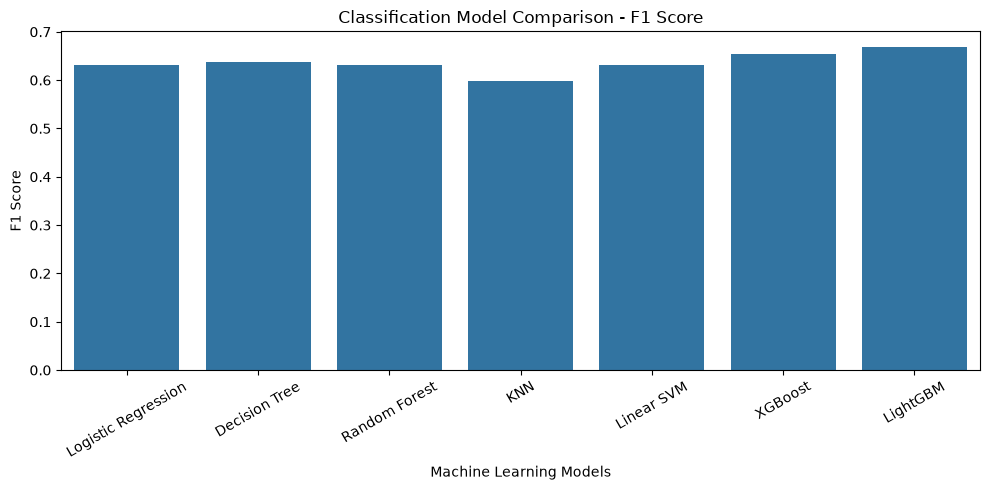

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=classification_results,
    x="Model",
    y="F1 Score"
)

plt.title("Classification Model Comparison - F1 Score")
plt.xlabel("Machine Learning Models")
plt.ylabel("F1 Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [20]:
# Get trained LightGBM model
lgb_model = lightgbm_classifier.named_steps["model"]

# Get feature names after preprocessing
feature_names = lightgbm_classifier.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance
importance_values = lgb_model.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
20,numerical__Hour,612
22,numerical__Month,599
21,numerical__DayOfWeek,301
19,numerical__ChargerCompany,256
18,numerical__ChargerType,177
7,categorical__Location_market,132
11,categorical__Location_resort,102
6,categorical__Location_hotel,94
1,categorical__Location_apartment,92
0,categorical__Location_accommodation,55


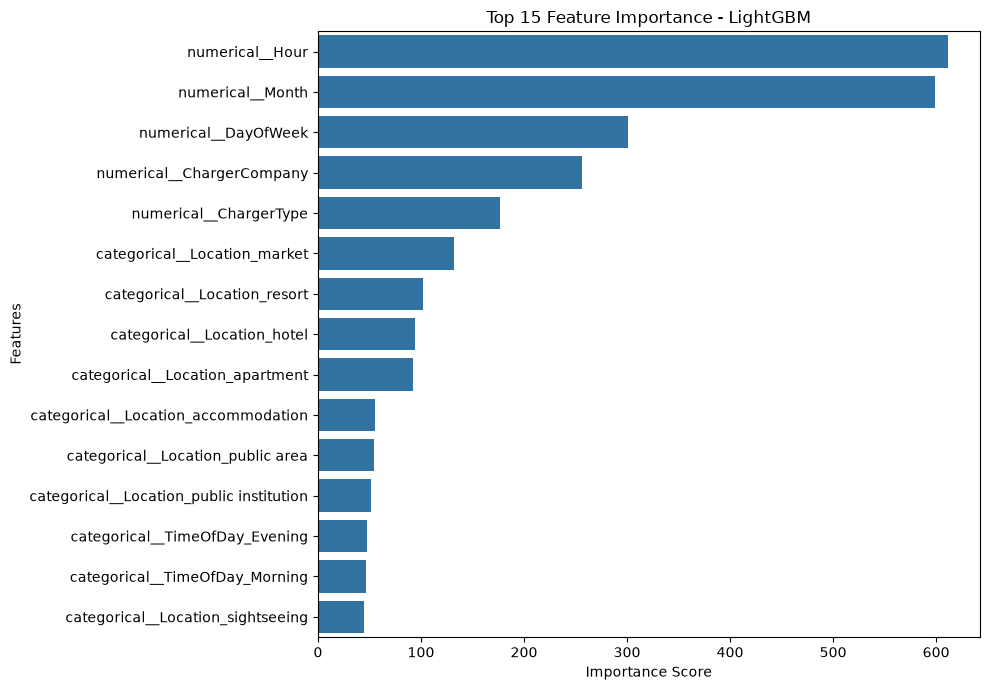

In [21]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importance - LightGBM")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [22]:
feature_importance.to_csv(
    "../dataset/feature_importance_results.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [23]:
!pip install shap

In [24]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1
